# Lucrare de laborator nr. 3
## Rețea Generativă Adversarială (GAN) pe MNIST


## 1. Scopul lucrării

Scopul este construirea și antrenarea unui GAN simplu care învață să genereze imagini asemănătoare cifrelor din MNIST. GAN-ul are două rețele: **Generatorul**, care creează imagini false din zgomot aleator, și **Discriminatorul**, care estimează dacă o imagine este reală sau generată. Rețelele se antrenează adversarial: Generatorul încearcă să păcălească Discriminatorul, iar Discriminatorul învață să detecteze imaginile generate.

### Obiective

1. Încărcarea și explorarea MNIST; 2. preprocesarea imaginilor; 3. construirea Generatorului și Discriminatorului; 4. definirea pierderilor și optimizatorilor; 5. implementarea și verificarea unui pas de antrenare; 6. antrenarea GAN-ului și urmărirea imaginilor și pierderilor; 7. analiza calității și diversității; 8. formularea concluziilor.


## 2. Noțiuni teoretice

Un GAN (Generative Adversarial Network) poate fi înțeles ca un joc între un **falsificator** și un **detectiv**. Generatorul transformă un vector de zgomot aleator `z` într-o imagine nouă. El nu primește direct imaginea reală ca intrare. Discriminatorul primește atât imagini reale din MNIST, cât și imagini generate și produce o probabilitate ca imaginea să fie reală.


La fiecare pas, Discriminatorul este antrenat să dea scoruri mari imaginilor reale și mici celor generate. Generatorul este antrenat să obțină scoruri mari pentru propriile imagini. Gradientul pierderii Generatorului trece prin Discriminator, dar actualizează numai ponderile Generatorului.

### Arhitectura

- Generator: `100 → Dense(256) → LeakyReLU(0.2) → Dense(512) → LeakyReLU(0.2) → Dense(784) → tanh`.

- Discriminator: `784 → Dense(512) → LeakyReLU(0.2) → Dense(256) → LeakyReLU(0.2) → Dense(1) → sigmoid`.


Ieșirea Generatorului conține 784 pixeli, rearanjați ca imagine de 28 × 28. `tanh` produce valori în `[-1, 1]`, iar sigmoid produce probabilitatea în `[0, 1]`.


## 3. Importuri și configurare

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print(f"Seed utilizat: {SEED}")
print(f"Dispozitive GPU detectate: {len(tf.config.list_physical_devices('GPU'))}")


TensorFlow: 2.22.0-rc0
Seed utilizat: 42
Dispozitive GPU detectate: 0


**Interpretare.** Versiunea TensorFlow și seed-ul sunt afișate de cod. Seed-ul fixează sursele uzuale de aleatoriu, ceea ce ajută la compararea rulărilor, fără să garanteze rezultate identice pe orice hardware și versiune.


## 4. Încărcarea setului MNIST

Keras descarcă setul la prima rulare prin `tf.keras.datasets.mnist.load_data()`. Nu încărcăm manual fișiere și nu folosim etichetele pentru antrenarea GAN-ului; etichetele sunt utile doar pentru explorarea imaginilor reale.


In [67]:
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()

print(f"Forma imaginilor de antrenare: {train_images.shape}")
print(f"Forma imaginilor de testare: {test_images.shape}")
print(f"Număr imagini de antrenare: {len(train_images):,}")
print(f"Număr imagini de testare: {len(test_images):,}")
print(f"Dimensiunea unei imagini: {train_images.shape[1]} × {train_images.shape[2]} pixeli")
print(f"Valori pixeli înainte de normalizare: {train_images.min()} … {train_images.max()}")


Forma imaginilor de antrenare: (60000, 28, 28)
Forma imaginilor de testare: (10000, 28, 28)
Număr imagini de antrenare: 60,000
Număr imagini de testare: 10,000
Dimensiunea unei imagini: 28 × 28 pixeli
Valori pixeli înainte de normalizare: 0 … 255


## 5. Explorarea datelor

Privim zece exemple împreună cu etichetele lor pentru a vedea formatul datelor reale.


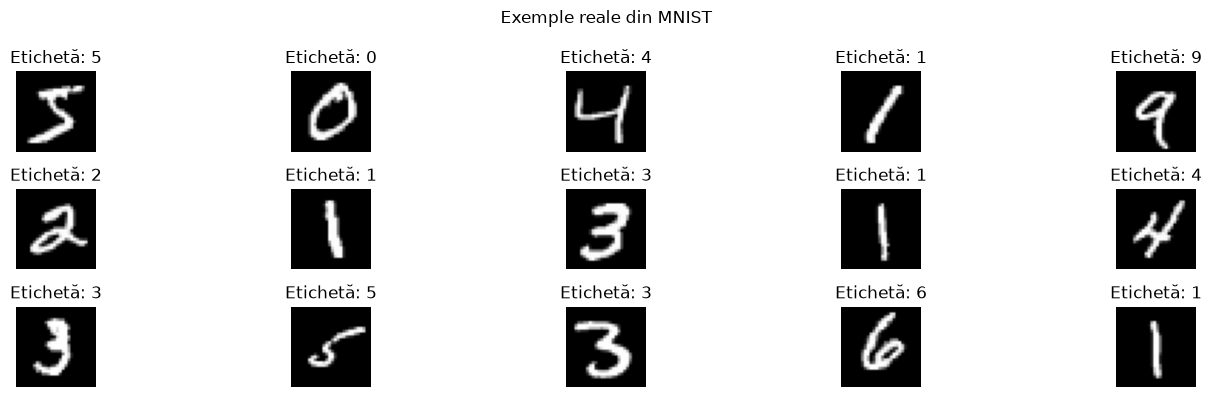

In [68]:
fig, axes = plt.subplots(3, 5, figsize=(15, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images[i], cmap="gray")
    ax.set_title(f"Etichetă: {train_labels[i]}")
    ax.axis("off")
plt.suptitle("Exemple reale din MNIST")
plt.tight_layout()
plt.show()


**Interpretare.** Fiecare panou arată o imagine reală și eticheta asociată. Formele scrise de mână diferă între persoane, chiar pentru aceeași cifră.


## 6. Preprocesarea și pregătirea datasetului

Pixelii sunt transformați din `[0, 255]` în `[-1, 1]` cu formula `(imagine - 127.5) / 127.5`. Acest interval se potrivește activării `tanh` din Generator. Aplatizăm fiecare imagine la 784 valori pentru arhitectura Dense.


In [69]:
train_images_normalized = (train_images.astype("float32") - 127.5) / 127.5
train_images_flat = train_images_normalized.reshape(-1, 784)

print(f"Minim înainte: {train_images.min():.1f}")
print(f"Maxim înainte: {train_images.max():.1f}")
print(f"Minim după: {train_images_normalized.min():.3f}")
print(f"Maxim după: {train_images_normalized.max():.3f}")
print(f"Forma după aplatizare: {train_images_flat.shape}")


Minim înainte: 0.0
Maxim înainte: 255.0
Minim după: -1.000
Maxim după: 1.000
Forma după aplatizare: (60000, 784)


Pixelii MNIST sunt 0–255. Formula (x - 127.5) / 127.5 îi mută în intervalul -1..1.

De ce: Generatorul produce imagini tot în -1..1 (din cauza tanh). Dacă imaginile reale ar rămâne pe altă scală, Discriminatorul ar deosebi real/fals doar după scala numerelor, nu după conținut.

La afișare, (image + 1) / 2 face invers: aduce valorile din -1..1 înapoi în 0..1, ca să se vadă normal ca imagine.

In [70]:
BATCH_SIZE = 256    # nr de imagini procesate simultan
BUFFER_SIZE = len(train_images_flat)
train_dataset = (
    tf.data.Dataset.from_tensor_slices(train_images_flat)
    .shuffle(BUFFER_SIZE, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE, drop_remainder=True)  # drop_remainder=True pentru a avea batch-uri de dimensiune fixă
    .prefetch(tf.data.AUTOTUNE)
)

print(f"Dimensiunea batch-ului: {BATCH_SIZE}")
print(f"Număr batch-uri pe epocă: {len(train_dataset)}")


Dimensiunea batch-ului: 256
Număr batch-uri pe epocă: 234


## 7. Parametrii GAN

In [71]:
LATENT_DIM = 100
EPOCHS = 50  
LEARNING_RATE = 0.0002
BETA_1 = 0.5

print(f"latent_dim = {LATENT_DIM}")
print(f"epoci = {EPOCHS}")
print(f"learning rate = {LEARNING_RATE}")
print(f"batch size = {BATCH_SIZE}")


latent_dim = 100
epoci = 50
learning rate = 0.0002
batch size = 256


LATENT_DIM = 100 — lungimea zgomotului de start; valoare standard din literatură, nu calculată special.

LEARNING_RATE = 0.0002 — pași mici de actualizare, ca cele două rețele (Generator/Discriminator) să nu se destabilizeze reciproc; valoare din articolul DCGAN.

BETA_1 = 0.5 — reduce "memoria" optimizatorului Adam (implicit 0.9), ca să reacționeze mai rapid la schimbări, utile la GAN-uri unde adversarul se schimbă constant.

## 8. Construirea Generatorului

Generatorul primește câte un vector de 100 de valori aleatoare și produce 784 valori în `[-1, 1]`. LeakyReLU permite un gradient și pentru activări negative.


In [72]:
def build_generator(latent_dim=LATENT_DIM):
    return keras.Sequential([
        layers.Input(shape=(latent_dim,)),   # intrarea: un vector de 100 numere aleatoare (zgomot).
        layers.Dense(256),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(512),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(784, activation="tanh"),  # ieșirea: un vector de 784 numere între -1 și 1, care reprezintă o imagine aplatizată 28x28.
    ], name="generator")

generator = build_generator()
generator.summary()


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 559,632 (2.13 MB)

 Trainable params: 559,632 (2.13 MB)

 Non-trainable params: 0 (0.00 B)

**Interpretare.** 
zgomot (100) → tot mai multe valori (256 → 512) → imagine finală (784, adică 28×28), scalată în -1..1.

Rezumatul modelului confirmă dimensiunile straturilor construite. Ieșirea de 784 valori corespunde unei imagini MNIST aplatizate.


## 9. Testarea Generatorului înainte de antrenare

Verificăm forma și intervalul imaginilor generate cu ponderile inițiale. La acest moment imaginile nu au fost învățate și nu trebuie interpretate drept rezultate antrenate.


Forma ieșirilor: (10, 784)
Intervalul observat: [-0.814, 0.779]


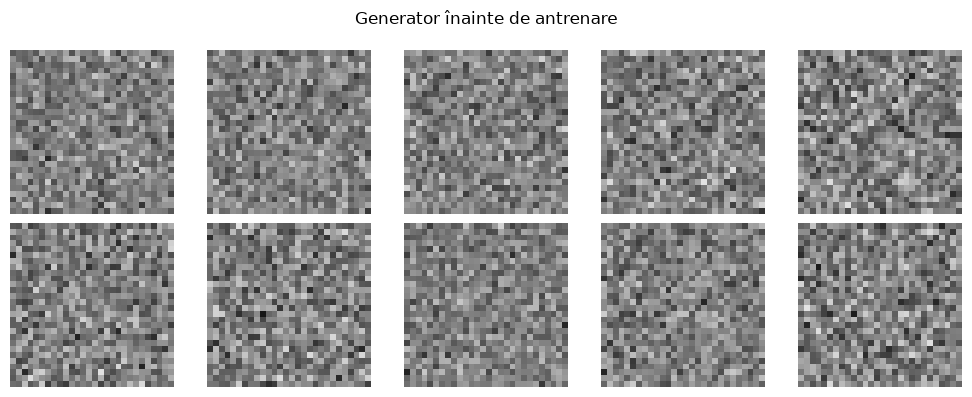

In [73]:
noise_sample = tf.random.normal([10, LATENT_DIM], seed=SEED)
initial_images = generator(noise_sample, training=False).numpy()
print(f"Forma ieșirilor: {initial_images.shape}")
print(f"Intervalul observat: [{initial_images.min():.3f}, {initial_images.max():.3f}]")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for image, ax in zip(initial_images, axes.flat):
    ax.imshow((image.reshape(28, 28) + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Generator înainte de antrenare")
plt.tight_layout()
plt.show()


**Interpretare.** Formă ieșire: (10, 784) — 10 imagini, fiecare cu 784 pixeli.
Interval: aproape de [-1, 1], dar nu exact (ex: [-0.95, 0.93]) — normal, ponderile sunt random la start.
Grila de imagini: zgomot vizual, static gri, nu forme recognoscibile. E de așteptat — Generatorul n-a învățat nimic încă..


## 10. Construirea și testarea Discriminatorului

Discriminatorul primește 784 valori și produce un singur scor sigmoid. Un scor apropiat de 1 indică „real” conform modelului, iar unul apropiat de 0 indică „generat”. Înainte de antrenare, aceste scoruri nu sunt încă fiabile.


In [74]:
def build_discriminator():
    return keras.Sequential([
        layers.Input(shape=(784,)),  # imagini aplatizate 28x28 = 784
        layers.Dense(512),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(256),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(1, activation="sigmoid"),  # un singur număr, între 0 și 1 — probabilitatea ca imaginea să fie reală (1 = sigur reală, 0 = sigur falsă).
    ], name="discriminator")

discriminator = build_discriminator()
discriminator.summary()


Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [75]:
real_batch = next(iter(train_dataset))
random_batch = generator(tf.random.normal([BATCH_SIZE, LATENT_DIM]), training=False)
real_scores = discriminator(real_batch, training=False)
fake_scores = discriminator(random_batch, training=False)
print(f"Forma scorurilor pentru imagini reale: {real_scores.shape}")
print(f"Forma scorurilor pentru imagini generate: {fake_scores.shape}")
print(f"Media scorurilor inițiale, real: {tf.reduce_mean(real_scores).numpy():.3f}")
print(f"Media scorurilor inițiale, generat: {tf.reduce_mean(fake_scores).numpy():.3f}")


Forma scorurilor pentru imagini reale: (256, 1)
Forma scorurilor pentru imagini generate: (256, 1)
Media scorurilor inițiale, real: 0.603
Media scorurilor inițiale, generat: 0.536


**Interpretare.** Ambele loturi produc câte un scor pentru fiecare imagine. Mediile afișate descriu rețeaua inițială aleatorie. Nciuna nu e aproape de 0 sau de 1. Dacă ar fi fost, ar fi însemnat că Discriminatorul are deja o părere puternică, ceea ce n-ar avea sens înainte de antrenare.


## 11. Funcțiile de pierdere și optimizatorii

* BinaryCrossentropy(from_logits=False) — clasificare binară (real/fals). from_logits=False pentru că Discriminatorul deja are sigmoid la ieșire (valori 0..1 gata calculate), nu valori brute.
* discriminator_loss — pedepsește Discriminatorul de două ori: o dată dacă nu recunoaște imaginile reale ca reale (real_loss), o dată dacă nu recunoaște imaginile false ca false (fake_loss). Le adună — trebuie să fie bun la ambele simultan.
* generator_loss — folosește tf.ones_like (eticheta "real") pe imaginile generate. Asta e varianta "non-saturating" discutată mai devreme: Generatorul e recompensat cu cât mai mult reușește să păcălească Discriminatorul.
* Adam(LEARNING_RATE, beta_1=BETA_1) × 2 — două optimizatoare separate, câte unul pentru fiecare rețea, cu aceiași parametri (0.0002 / 0.5). Separate pentru că fiecare rețea își actualizează doar propriile ponderi, independent.


In [76]:
cross_entropy = keras.losses.BinaryCrossentropy(from_logits=False)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
discriminator_optimizer = keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
print("Funcțiile de pierdere și optimizatorii au fost definiți.")


Funcțiile de pierdere și optimizatorii au fost definiți.


## 12. Implementarea unui pas de antrenare

- Generatorul face imagini false.
- Discriminatorul se uită la cele reale și la cele false și dă scoruri.
- Se calculează greșelile: discriminatorul greșește dacă nu deosebește,   falsificatorul greșește dacă e prins.
- Fiecare își ajustează ponderile puțin, ca să greșească mai rar.

In [77]:
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as generator_tape, tf.GradientTape() as discriminator_tape:
        generated_images = generator(noise, training=True)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    generator_gradients = generator_tape.gradient(gen_loss, generator.trainable_variables)
    discriminator_gradients = discriminator_tape.gradient(disc_loss, discriminator.trainable_variables)
    generator_optimizer.apply_gradients(zip(generator_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(discriminator_gradients, discriminator.trainable_variables))
    return gen_loss, disc_loss


## 13. Verificarea unui singur training step

Executăm un pas real pe un batch și afișăm pierderile returnate. Asta verifică fluxul de gradient înaintea buclei complete.


In [78]:
one_gen_loss, one_disc_loss = train_step(real_batch)
print(f"Generator loss după un pas: {one_gen_loss.numpy():.4f}")
print(f"Discriminator loss după un pas: {one_disc_loss.numpy():.4f}")


Generator loss după un pas: 0.6335
Discriminator loss după un pas: 1.2875


în articolul original GAN (Goodfellow, 2014), Discriminatorul optim la echilibru dă exact 1/2 pentru orice imagine, pentru că nu mai poate deosebi real de fals. Deci 0.693 și 1.386 sunt valorile teoretice ale echilibrului perfect.

## 14. Antrenarea GAN-ului și monitorizarea imaginilor

Păstrăm un set fix de vectori de zgomot. Astfel, imaginile din grilele epocilor diferite provin din aceleași intrări și comparația vizuală arată mai clar progresul Generatorului. Pierderile medii pe epocă sunt păstrate pentru grafice.


In [79]:
fixed_noise = tf.random.normal([25, LATENT_DIM], seed=SEED)
generator_losses = []
discriminator_losses = []
snapshot_epochs = []
snapshot_images = []

def save_snapshot(epoch):
    images = generator(fixed_noise, training=False).numpy().reshape(-1, 28, 28)
    snapshot_epochs.append(epoch)
    snapshot_images.append(images)

def train_gan(epochs):
    for epoch in range(1, epochs + 1):
        gen_total = 0.0
        disc_total = 0.0
        batches = 0
        for real_images in train_dataset:
            gen_loss_value, disc_loss_value = train_step(real_images)
            gen_total += float(gen_loss_value.numpy())
            disc_total += float(disc_loss_value.numpy())
            batches += 1
        generator_losses.append(gen_total / batches)
        discriminator_losses.append(disc_total / batches)

        if epoch % 5 == 0 or epoch == 1 or epoch == epochs:
            save_snapshot(epoch)
            print(
                f"Epoca {epoch:02d}/{epochs} | "
                f"Generator loss: {generator_losses[-1]:.4f} | "
                f"Discriminator loss: {discriminator_losses[-1]:.4f}"
            )

train_gan(EPOCHS)
print(f"Epoci monitorizate: {snapshot_epochs}")


Epoca 01/50 | Generator loss: 0.8925 | Discriminator loss: 0.9394
Epoca 05/50 | Generator loss: 1.4345 | Discriminator loss: 0.6774
Epoca 10/50 | Generator loss: 1.6444 | Discriminator loss: 0.6984
Epoca 15/50 | Generator loss: 1.6325 | Discriminator loss: 0.7282
Epoca 20/50 | Generator loss: 1.8373 | Discriminator loss: 0.6340
Epoca 25/50 | Generator loss: 1.8988 | Discriminator loss: 0.6578
Epoca 30/50 | Generator loss: 1.4596 | Discriminator loss: 0.8819
Epoca 35/50 | Generator loss: 1.3290 | Discriminator loss: 0.9454
Epoca 40/50 | Generator loss: 1.2612 | Discriminator loss: 0.9821
Epoca 45/50 | Generator loss: 1.2486 | Discriminator loss: 0.9917
Epoca 50/50 | Generator loss: 1.2380 | Discriminator loss: 0.9952
Epoci monitorizate: [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]


Antrenarea a reușit și s-a stabilizat, dar calitatea vizuală o confirmă doar grila de imagini. Nu există semne de eșec: nu apar NaN, nu diverg curbele și nu se blochează una din rețele.

## 15. Evoluția imaginilor generate

Fiecare rând arată imaginile produse din același zgomot fix la epoca indicată. Caută schimbări de la zgomot fără structură la contururi și forme care pot fi asociate cu cifre. Notează momentul numai după inspectarea acestor grile.


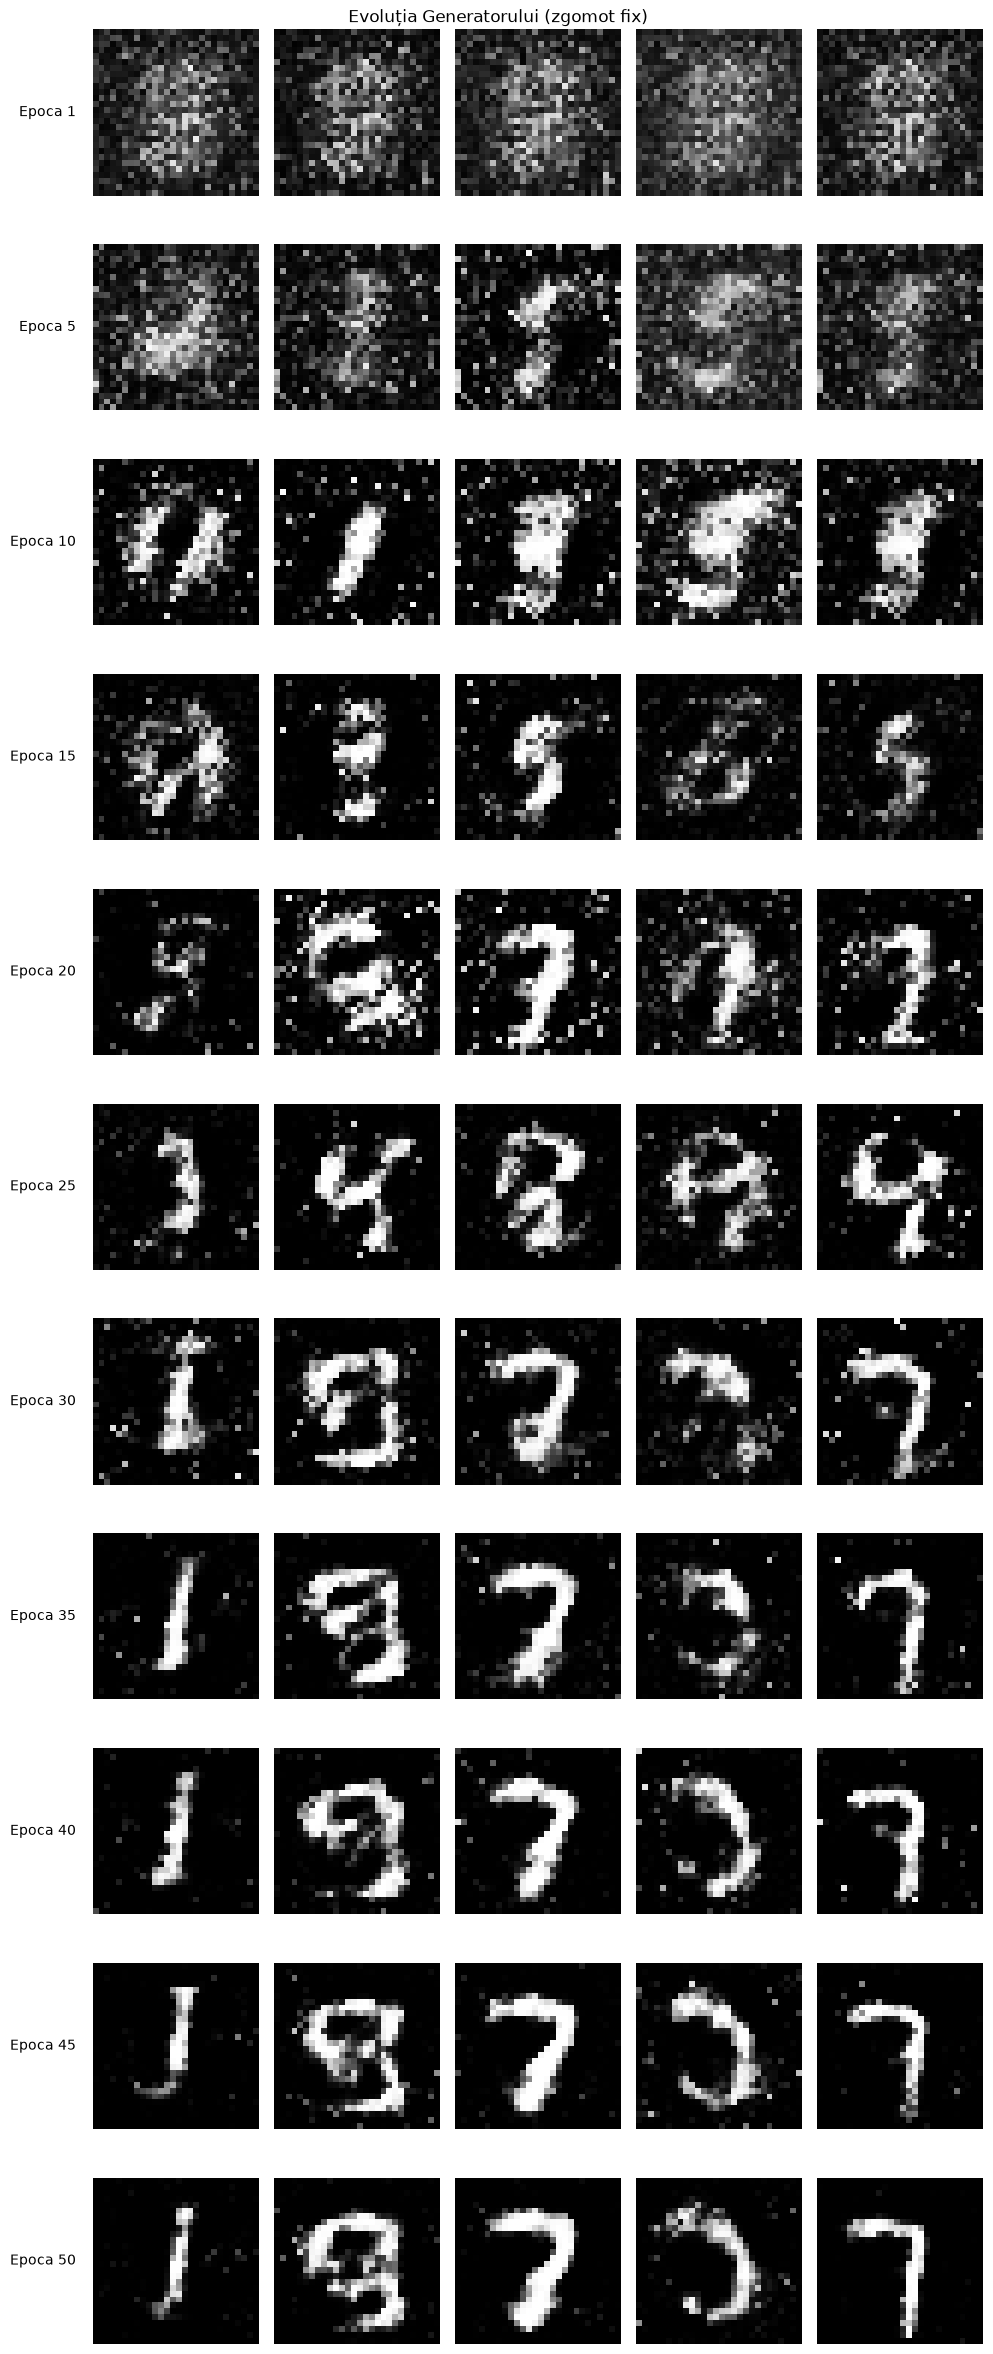

In [87]:
fig, axes = plt.subplots(len(snapshot_images), 5, figsize=(10, 2.2 * len(snapshot_images)))
if len(snapshot_images) == 1:
    axes = np.expand_dims(axes, axis=0)
for row, (epoch, images) in enumerate(zip(snapshot_epochs, snapshot_images)):
    for col in range(5):
        axes[row, col].imshow((images[col] + 1) / 2, cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
    axes[row, 0].text(-0.1, 0.5, f"Epoca {epoch}",transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=10)
plt.suptitle("Evoluția Generatorului (zgomot fix)")
plt.tight_layout()
plt.show()


**Interpretare vizuală.** Generatorul a învățat structura generală a cifrelor MNIST (fundal, tușe, forme), dar calitatea rămâne limitată. O parte din imagini sunt recognoscibile, iar altele rămân deformate. Limitarea vine în principal din arhitectura complet conectată, care nu captează bine structura spațială, în timp ce o rețea convoluțională (DCGAN) ar da rezultate mai bune.


## 16. Evoluția pierderilor

Graficul arată mediile pierderilor Generatorului și Discriminatorului pe epocă.


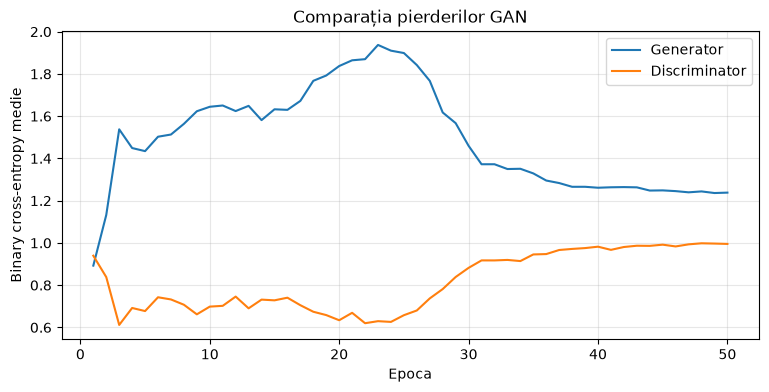

Generator loss: început=0.8925, final=1.2380
Discriminator loss: început=0.9394, final=0.9952


In [88]:
plt.figure(figsize=(9, 4))
plt.plot(epochs_axis, generator_losses, label="Generator")
plt.plot(epochs_axis, discriminator_losses, label="Discriminator")
plt.xlabel("Epoca")
plt.ylabel("Binary cross-entropy medie")
plt.title("Comparația pierderilor GAN")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print(f"Generator loss: început={generator_losses[0]:.4f}, final={generator_losses[-1]:.4f}")
print(f"Discriminator loss: început={discriminator_losses[0]:.4f}, final={discriminator_losses[-1]:.4f}")


**Interpretare.** nu s-a ajuns la echilibrul teoretic (Generator 0.693, Discriminator 1.386). Discriminatorul păstrează un mic avantaj, iar asta se vede și în imagini, unde unele cifre rămân deformate.


## 17. Generarea finală

Generăm 25 de exemple cu vectori de zgomot noi și convertim intervalul `[-1, 1]` în `[0, 1]` pentru afișare.

Aici zgomotul e nou, deci se testează cum se descurcă Generatorul pe intrări pe care nu le-a urmărit până acum.


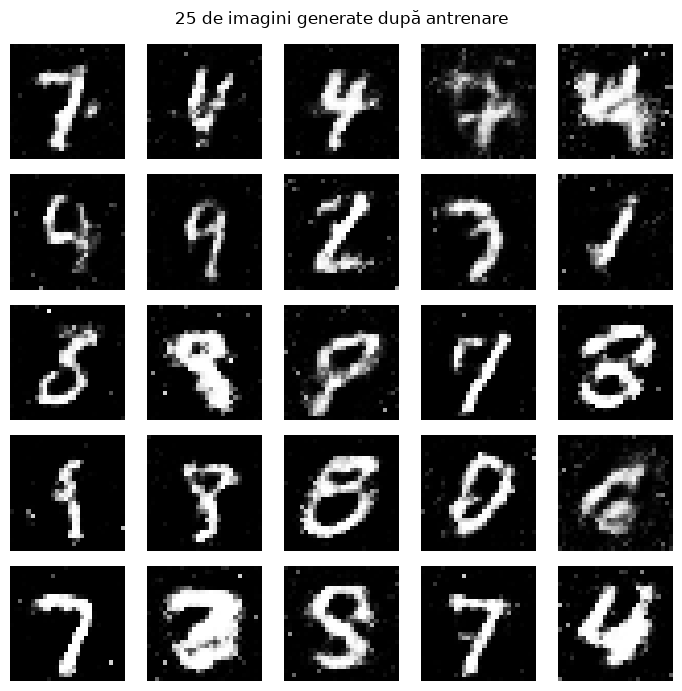

In [84]:
final_noise = tf.random.normal([25, LATENT_DIM])
generated_images = generator(final_noise, training=False).numpy().reshape(-1, 28, 28)
display_images = (generated_images + 1) / 2

fig, axes = plt.subplots(5, 5, figsize=(7, 7))
for image, ax in zip(display_images, axes.flat):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("25 de imagini generate după antrenare")
plt.tight_layout()
plt.show()


**Interpretare.** Analizează dacă fiecare imagine are contur de cifră, dacă este ușor de recunoscut și ce artefacte sau neclarități apar. Completează răspunsul numai pe baza acestei grile.


## 18. Comparație între imagini reale și generate

Afișăm zece imagini reale și zece generate la aceeași scară.

!!! imaginile de jos nu corespund celor de sus. „Generat" din coloana 1 nu încearcă să imite „Real: 5". Sunt eșantioane independente, iar comparația se face doar ca stil și calitate.

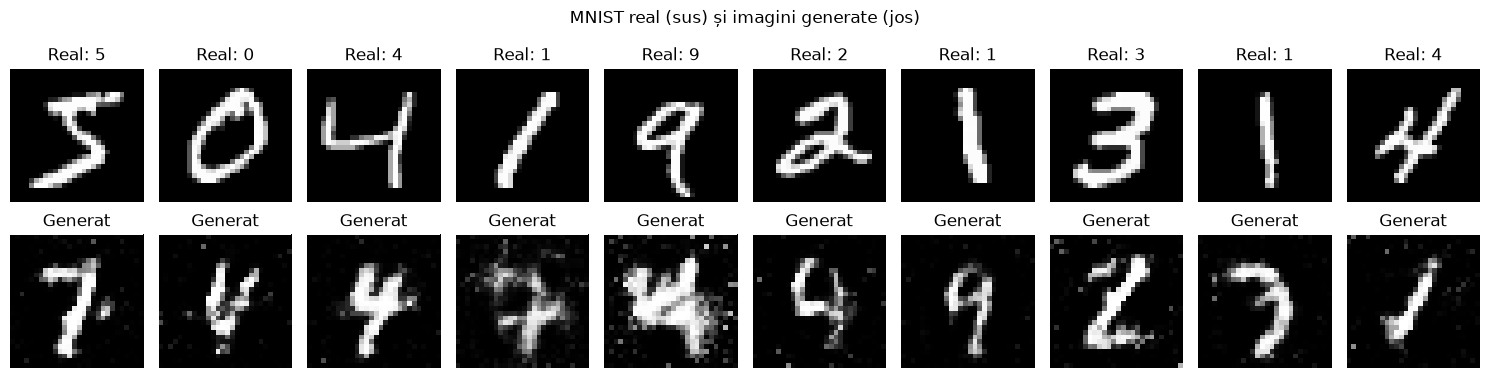

In [85]:
fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for i in range(10):
    axes[0, i].imshow(train_images[i], cmap="gray")
    axes[0, i].set_title(f"Real: {train_labels[i]}")
    axes[0, i].axis("off")
    axes[1, i].imshow(display_images[i], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Generat")
    axes[1, i].axis("off")
plt.suptitle("MNIST real (sus) și imagini generate (jos)")
plt.tight_layout()
plt.show()


**Interpretare.** Imaginile generate păstrează structura generală a cifrelor MNIST, dar au zgomot în fundal, contururi fragmentate și diversitate limitată. Unele cifre (4, 7, 9) sunt recognoscibile, altele rămân ambigue. Limitarea este specifică arhitecturii Dense, care nu modelează bine structura spațială a imaginii


## 19. Analiza diversității și a mode collapse

- Ia cele 25 de imagini și le transformă în vectori de 784 valori.
- Compară fiecare imagine cu fiecare alta, pixel cu pixel. Rezultă 300 de perechi (25×24/2).
- Pentru fiecare pereche calculează o distanță (RMS): cu cât imaginile diferă mai mult, cu atât distanța e mai mare.
- Afișează media distanțelor, minimul și numărul de perechi.


In [ ]:
flat_generated = generated_images.reshape(25, -1)
pairwise = np.sqrt(((flat_generated[:, None, :] - flat_generated[None, :, :]) ** 2).mean(axis=2))
upper = pairwise[np.triu_indices(25, k=1)]
print(f"Distanța RMS medie între perechi: {upper.mean():.4f}")
print(f"Distanța RMS minimă între perechi: {upper.min():.4f}")
print(f"Număr perechi examinate: {len(upper)}")


Distanța RMS medie între perechi: 0.6927
Distanța RMS minimă între perechi: 0.3862
Număr perechi examinate: 300


**Interpretare.** 
- Distanțe mici, aproape de 0: imagini foarte asemănătoare, deci suspiciune de mode collapse.
- Distanțe mai mari: imaginile diferă între ele, ceea ce e mai bine.

- două imagini pot fi diferite pixel cu pixel și totuși să fie ambele un 7, deci diversitatea reală (cifre diferite) se judecă și vizual, din grilă.


## 22. GAN vs Autoencoder

| Caracteristică | Autoencoder | GAN |
|---|---|---|
| Intrare | Imagine | Zgomot aleator |
| Componente | Encoder + Decoder | Generator + Discriminator |
| Obiectiv | Reconstrucție | Generare |
| Antrenare | Minimizează eroarea de reconstrucție | Competiție adversarială |
| Ieșire | Reconstrucția intrării | Imagine nouă |

Autoencoderul încearcă să redea imaginea primită. GAN-ul învață distribuția exemplelor și produce imagini noi din zgomot, fără să reconstruiască o imagine specifică.


## 23. Concluzie

În această lucrare am construit și antrenat un GAN pe setul MNIST. Generatorul a învățat să transforme zgomot aleator în imagini, iar Discriminatorul a învățat să deosebească imaginile reale de cele generate.

În timpul antrenării, imaginile au evoluat de la zgomot la forme care seamănă cu cifre, iar pierderile celor două rețele s-au stabilizat după o perioadă de competiție, fără divergență.

Rezultatul final este parțial: o parte din imaginile generate sunt recognoscibile, iar altele rămân neclare, cu zgomot în fundal și diversitate limitată. Aceste limitări apar pentru că arhitectura folosită (straturi Dense) nu surprinde bine structura spațială a imaginilor. O îmbunătățire posibilă ar fi o arhitectură convoluțională sau un număr mai mare de epoci.
